In [54]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.pylab as pylab
import re
import bs4 as bs
import gensim
from gensim.models import Word2Vec
from nltk.tokenize import sent_tokenize,word_tokenize
import nltk
import urllib.request
%matplotlib inline
import seaborn as sns

In [55]:
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Sanika\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Sanika\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Sanika\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [56]:
sentences = """Alice 23 opened the door and found that it led into a small 90
passage, not much larger than a rat-hole: she knelt down and
looked along the passage into the loveliest garden you ever saw.
How she longed to get out of that dark hall, and wander about
among those beds of bright flowers and those cool fountains, but
she could not even get her head through the doorway; `and even if
my head would go through,' (thought) $poor Alice, `it would be of
very little use without my shoulders. Oh, how I wish
I could shut up like a telescope! I think I could, if I only
know how to begin.' For, you see, so many out-of-the-way things
had happened lately, that Alice had begun to think that very few
things indeed were really impossible."""

In [57]:
sentences=re.sub('[^A-Za-z]+', ' ' , sentences)

In [58]:
sentences=re.sub(r'(?:^| )\w(?:$| )', ' ' , sentences).strip()
sentences=sentences.lower()
print(sentences)

alice opened the door and found that it led into small passage not much larger than rat hole she knelt down and looked along the passage into the loveliest garden you ever saw how she longed to get out of that dark hall and wander about among those beds of bright flowers and those cool fountains but she could not even get her head through the doorway and even if my head would go through thought poor alice it would be of very little use without my shoulders oh how wish could shut up like telescope think could if only know how to begin for you see so many out of the way things had happened lately that alice had begun to think that very few things indeed were really impossible


In [67]:
all_sent=nltk.sent_tokenize(sentences)
all_words=[nltk.word_tokenize(word) for word in all_sent]
from nltk.corpus import stopwords
for i in range(len(all_words)):
    all_words[i]=[w for w in all_words[i] if w not in stopwords.words('english')]
    data=all_words
    data1=data[0]

In [68]:
model1=gensim.models.Word2Vec(data, min_count=1,vector_size=52,window=5)

In [69]:
vocabolary=model1.wv.key_to_index
vocabolary

{'could': 0,
 'alice': 1,
 'things': 2,
 'think': 3,
 'would': 4,
 'head': 5,
 'even': 6,
 'get': 7,
 'passage': 8,
 'impossible': 9,
 'really': 10,
 'indeed': 11,
 'begun': 12,
 'lately': 13,
 'happened': 14,
 'way': 15,
 'many': 16,
 'see': 17,
 'begin': 18,
 'know': 19,
 'telescope': 20,
 'like': 21,
 'shut': 22,
 'wish': 23,
 'oh': 24,
 'shoulders': 25,
 'without': 26,
 'use': 27,
 'little': 28,
 'poor': 29,
 'thought': 30,
 'go': 31,
 'doorway': 32,
 'fountains': 33,
 'cool': 34,
 'flowers': 35,
 'bright': 36,
 'beds': 37,
 'among': 38,
 'wander': 39,
 'hall': 40,
 'dark': 41,
 'longed': 42,
 'saw': 43,
 'ever': 44,
 'garden': 45,
 'loveliest': 46,
 'along': 47,
 'looked': 48,
 'knelt': 49,
 'hole': 50,
 'rat': 51,
 'larger': 52,
 'much': 53,
 'small': 54,
 'led': 55,
 'found': 56,
 'door': 57,
 'opened': 58}

In [74]:
wrd='along'
v1=model1.wv[wrd]
sim=model1.wv.most_similar(wrd)
for x in sim:
 print(x)

('looked', 0.31171876192092896)
('use', 0.2966703176498413)
('thought', 0.25894615054130554)
('things', 0.24750450253486633)
('garden', 0.2334156185388565)
('head', 0.23284168541431427)
('without', 0.19903376698493958)
('even', 0.1601371318101883)
('cool', 0.15985573828220367)
('much', 0.1595705896615982)


In [84]:
print(data1)
dat=[]
for i in range(2,len(data1)-2):
  context=[data1[i-2],data1[i-1],data1[i+1],data1[i+2]]
  target =data1[i]
  dat.append((context,target))
print(dat[:5])
if len(dat)>1:
  print(dat[1][0])
else:
    print("no enought data")

['alice', 'opened', 'door', 'found', 'led', 'small', 'passage', 'much', 'larger', 'rat', 'hole', 'knelt', 'looked', 'along', 'passage', 'loveliest', 'garden', 'ever', 'saw', 'longed', 'get', 'dark', 'hall', 'wander', 'among', 'beds', 'bright', 'flowers', 'cool', 'fountains', 'could', 'even', 'get', 'head', 'doorway', 'even', 'head', 'would', 'go', 'thought', 'poor', 'alice', 'would', 'little', 'use', 'without', 'shoulders', 'oh', 'wish', 'could', 'shut', 'like', 'telescope', 'think', 'could', 'know', 'begin', 'see', 'many', 'way', 'things', 'happened', 'lately', 'alice', 'begun', 'think', 'things', 'indeed', 'really', 'impossible']
[(['alice', 'opened', 'found', 'led'], 'door'), (['opened', 'door', 'led', 'small'], 'found'), (['door', 'found', 'small', 'passage'], 'led'), (['found', 'led', 'passage', 'much'], 'small'), (['led', 'small', 'much', 'larger'], 'passage')]
['opened', 'door', 'led', 'small']


In [87]:
for val in dat:
    print(val[1],val[0])
    i=3
if len(dat)>3:
    print(dat[i])
    print(model1.predict_output_word(dat[i][0]))
else:
    print("no index")
    
    

door ['alice', 'opened', 'found', 'led']
found ['opened', 'door', 'led', 'small']
led ['door', 'found', 'small', 'passage']
small ['found', 'led', 'passage', 'much']
passage ['led', 'small', 'much', 'larger']
much ['small', 'passage', 'larger', 'rat']
larger ['passage', 'much', 'rat', 'hole']
rat ['much', 'larger', 'hole', 'knelt']
hole ['larger', 'rat', 'knelt', 'looked']
knelt ['rat', 'hole', 'looked', 'along']
looked ['hole', 'knelt', 'along', 'passage']
along ['knelt', 'looked', 'passage', 'loveliest']
passage ['looked', 'along', 'loveliest', 'garden']
loveliest ['along', 'passage', 'garden', 'ever']
garden ['passage', 'loveliest', 'ever', 'saw']
ever ['loveliest', 'garden', 'saw', 'longed']
saw ['garden', 'ever', 'longed', 'get']
longed ['ever', 'saw', 'get', 'dark']
get ['saw', 'longed', 'dark', 'hall']
dark ['longed', 'get', 'hall', 'wander']
hall ['get', 'dark', 'wander', 'among']
wander ['dark', 'hall', 'among', 'beds']
among ['hall', 'wander', 'beds', 'bright']
beds ['wander'

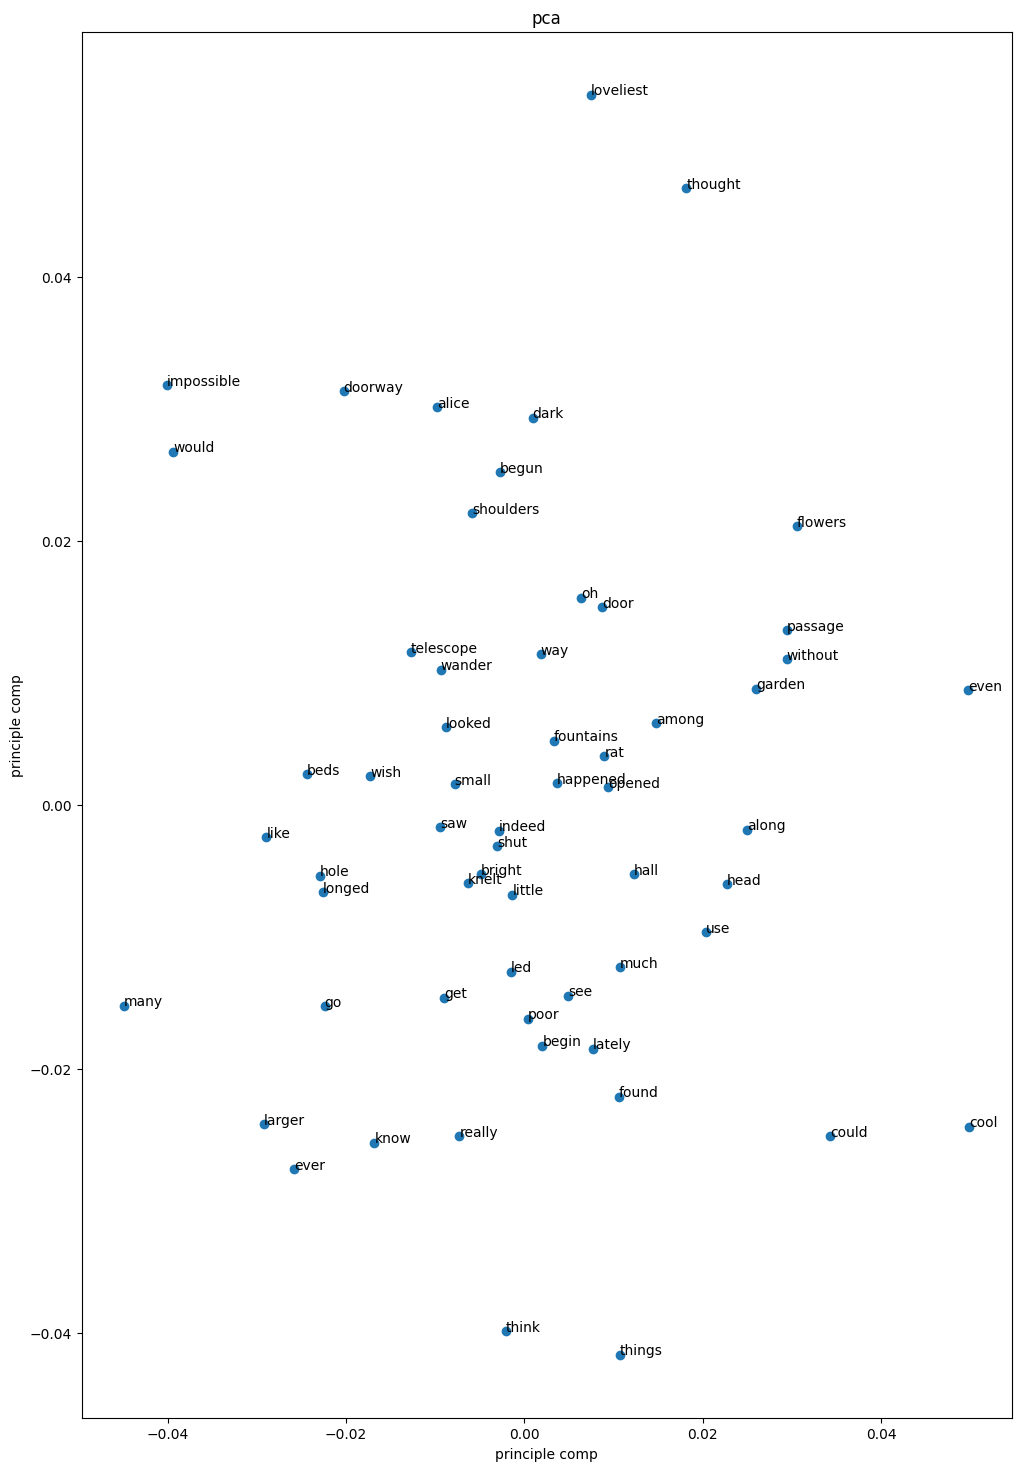

In [95]:
from sklearn.decomposition import PCA
words=model1.wv.index_to_key
X=model1.wv[words]
pca=PCA(n_components=2)
result=pca.fit_transform(X)
plt.figure(figsize=(12,18))
plt.scatter(result[:,0],result[:,1])
for i,word in enumerate(words):
    plt.annotate(word,xy=(result[i,0],result[i,1]))
plt.xlabel('principle comp')
plt.ylabel('principle comp')
plt.title('pca')
plt.show()

    
